> 📄 **Versión ya ejecutada**, con los resultados y los análisis de Gemini del ejemplo, para leer sin correr nada. Para ejecutarla tú, abre la versión sin resultados: [`taller/pista_A_huracan.ipynb`](https://colab.research.google.com/github/alcastaro/codigo-que-salva-vidas/blob/main/taller/pista_A_huracan.ipynb).

# 🌀 Pista A — El huracán: de 50 futuros posibles a una alerta
**Código que Salva Vidas · DevFest Santo Domingo 2026 · Taller · Nivel principiante**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alcastaro/codigo-que-salva-vidas/blob/main/taller/pista_A_huracan.ipynb)

El 28 de octubre de 2025, **Melissa** tocó tierra en Jamaica como huracán categoría 5, con vientos de 160 nudos (unos 300 km/h). Fue el más fuerte que ha golpeado la isla.
Según Google DeepMind, su modelo **WeatherNext** anticipó esa llegada como categoría 5 **cinco días antes, con un 80 % de confianza**.

En esta pista haces tú lo que hicieron los pronosticadores:

| Paso | Qué haces | Producto de Google |
|---|---|---|
| 1 | Ver los **50 escenarios** que el modelo de IA dibujó días antes | Weather Lab (DeepMind) |
| 2 | Calcular la **probabilidad** de que el ojo pase cerca de un lugar | Weather Lab |
| 3 | Convertir todo en una **alerta** que se entienda en 3 segundos | Gemini y Gemma |
| 4 | **Adaptar** el cuaderno a otro huracán y a tu ciudad | Weather Lab en vivo |

**No necesitas saber programar.** Ejecuta cada celda con ▶️ (o `Shift + Enter`) en orden y lee el texto de arriba.

## ✅ Antes de empezar (3 minutos)

1. **Inicia sesión** en Colab con tu cuenta de Google (arriba a la derecha). Es lo único que necesitas: no hace falta proyecto de Google Cloud ni tarjeta.
2. **Guarda tu copia:** menú **File → Save a copy in Drive** (*Archivo → Guardar una copia en Drive*). Así tus cambios se guardan y la copia es tuya. Trabaja en esa copia.
3. **Ejecuta las celdas en orden**, de arriba abajo: haz clic en una celda y pulsa ▶️ a su izquierda, o `Shift + Enter`. Cuando la celda termina aparece una ✔️ verde.
4. La primera vez que ejecutes una celda, Colab avisa *"This notebook was not authored by Google"* (*"Este notebook no lo creó Google"*). Pulsa **Run anyway** (*Ejecutar de todos modos*).
5. Las celdas con un formulario a la derecha (desplegables, deslizadores, casillas) se pueden cambiar **sin tocar el código**.

> Los menús aparecen en inglés o en español según el idioma de tu cuenta. Aquí van en inglés, con el español entre paréntesis.

**Todo el código está en este cuaderno.** Cada paso define primero sus funciones (con comentarios que explican qué hace cada parte) y luego las usa. Puedes leerlas, cambiarlas y volver a ejecutarlas.

**¿De dónde salen los datos?** De la carpeta [`data/`](https://github.com/alcastaro/codigo-que-salva-vidas/tree/main/data) del repositorio en GitHub. La función `download()` de la primera celda baja cada archivo la primera vez que hace falta y lo guarda en la carpeta `workshop_data/` de tu sesión (panel 📁 de la izquierda). No tienes que subir ni descargar nada a mano.

In [1]:
# Paso 0 · Preparar el entorno (~20 s)
# Colab ya trae numpy, pandas y matplotlib. Solo falta la librería de Gemini.
!pip -q install -U google-genai

import gzip, json, math, os, time, urllib.request
from pathlib import Path
import numpy as np                 # cálculo con arreglos de números
import pandas as pd                # tablas
import matplotlib.pyplot as plt    # gráficos
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# ---------------------------------------------------------------- descargas
# Todos los datos del taller están en la carpeta data/ del repositorio en GitHub.
# Si haces un fork del repositorio, cambia esta dirección por la de tu copia.
REPO_RAW = os.environ.get("WORKSHOP_RAW", "https://raw.githubusercontent.com/alcastaro/codigo-que-salva-vidas/main")
DATA_DIR = Path("workshop_data")   # aquí se guardan las descargas (panel 📁 de la izquierda)


def download(path, url=None):
    """Baja un archivo una sola vez y devuelve su ruta local.

    path: ruta dentro de data/ del repositorio (por ejemplo "data/melissa/archivo.csv").
    url:  opcional, una dirección completa de otro sitio; se guarda en workshop_data/<path>.
    """
    local = DATA_DIR / path
    if not local.exists():                      # si ya está descargado, no lo baja otra vez
        local.parent.mkdir(parents=True, exist_ok=True)
        request = urllib.request.Request(url or f"{REPO_RAW}/{path}", headers={"User-Agent": "colab-workshop"})
        with urllib.request.urlopen(request, timeout=120) as response:
            local.write_bytes(response.read())
        print(f"⬇️  {path} · {local.stat().st_size / 1e6:.1f} MB")
    return local

print("Listo ✅")

Listo ✅


### 🔑 Tu API key de Gemini (2 minutos, solo la primera vez)
Si ya la guardaste, salta este bloque. Si no:
1. Abre **[aistudio.google.com/apikey](https://aistudio.google.com/apikey)** con tu cuenta de Google, acepta los términos y pulsa **Create API key**. Es gratis. Copia la key.
2. En Colab, abre el panel de la **llave 🔑 (Secretos)** en la barra de la izquierda.
3. Pulsa **Add new secret** (*Agregar secreto nuevo*). En *Name* escribe exactamente `GOOGLE_API_KEY` y en *Value* pega tu key.
4. Activa el interruptor **Notebook access** (*Acceso al notebook*) de esa fila.
5. Cuando ejecutes la siguiente celda, Colab puede preguntarte si este notebook puede usar el secreto: pulsa **Grant access** (*Otorgar acceso*).

> Atajo: en ese mismo panel, **Gemini API keys → Import key from Google AI Studio** crea y guarda la key por ti.
>
> **Nunca pegues una key dentro de una celda.** Si compartes el notebook o lo subes a GitHub, la key viaja con él y otra persona puede gastar tu cuota.

### 🤖 Conectar con Gemini
La siguiente celda define cómo hablar con Gemini y dos funciones de análisis: `analyze_figure()` le enseña una figura y `analyze_data()` le pasa unos números.
Las usamos después de cada resultado para tener una **segunda lectura**. Gemini puede equivocarse: compárala siempre con la tuya y con el bloque 🔎.

In [2]:
# ---------------------------------------------------------------- Gemini
import logging
from google import genai
from google.genai import types

# La librería avisa en inglés sobre una función que no usamos; para este taller es solo ruido.
logging.getLogger("google_genai.models").setLevel(logging.ERROR)


def gemini_client():
    """Crea el cliente de la API de Gemini con la key guardada en los Secretos de Colab."""
    try:
        from google.colab import userdata          # solo existe dentro de Colab
        key = userdata.get("GOOGLE_API_KEY")
    except ImportError:                             # fuera de Colab: variable de entorno
        key = os.environ.get("GOOGLE_API_KEY")
    except Exception as error:
        raise RuntimeError("No encuentro tu key. Abre la llave 🔑 (Secretos), crea GOOGLE_API_KEY "
                           "y activa 'Notebook access'.") from error
    if not key:
        raise RuntimeError("Falta GOOGLE_API_KEY. Sácala gratis en aistudio.google.com/apikey.")
    return genai.Client(api_key=key)


# Modelos con cuota gratuita, en orden de preferencia. Se usa el primero que tu key tenga disponible.
PREFERRED_MODELS = {
    "flash": ["gemini-flash-latest", "gemini-flash-lite-latest", "gemini-2.5-flash"],
    "gemma": ["gemma-4-26b-a4b-it", "gemma-4-31b-it"],
}


def pick_model(client, family="flash"):
    """Devuelve el primer modelo preferido que aparece en la lista de modelos de tu key."""
    available = {m.name.split("/")[-1] for m in client.models.list()}
    for name in PREFERRED_MODELS[family]:
        if name in available:
            return name
    return PREFERRED_MODELS[family][0]


def generate(client, model, contents, config=None, attempts=4):
    """Llama al modelo. Si está saturado (503) o llegaste al límite por minuto (429), espera y reintenta.
    En el último intento usa la versión 'lite', que suele tener más capacidad libre."""
    fallback = {"gemini-flash-latest": "gemini-flash-lite-latest"}
    last_error = None
    for attempt in range(attempts):
        current = model if attempt < attempts - 1 else fallback.get(model, model)
        try:
            return client.models.generate_content(model=current, contents=contents, config=config)
        except Exception as error:
            last_error = error
            if not any(code in str(error) for code in ("429", "503", "500", "UNAVAILABLE", "RESOURCE_EXHAUSTED")):
                raise                               # otro tipo de error: lo mostramos tal cual
            print(f"   modelo ocupado, reintento {attempt + 1}…")
            time.sleep(4 * (attempt + 1))
    raise last_error

# ---------------------------------------------------------------- análisis con Gemini
import io
from IPython.display import Markdown, display

ANALYST_RULES = ("Eres analista de datos para gestión de riesgos de desastre. Explica en español sencillo, en 4 a 6 "
                 "viñetas: qué muestra, qué patrón se ve, qué conclusión prudente se puede sacar y qué habría que "
                 "verificar en terreno. Separa lo que se VE de lo que se INTERPRETA. No inventes cifras que no estén "
                 "en la figura o en el contexto. Si algo no se puede saber con estos datos, dilo.")


def analyze_figure(fig, context):
    """Le enseña la figura a Gemini (que entiende imágenes) y le pide que la analice."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=80, bbox_inches="tight")   # la figura como imagen PNG
    image = types.Part.from_bytes(data=buffer.getvalue(), mime_type="image/png")
    response = generate(client, model, [image, ANALYST_RULES + "\nContexto: " + context])
    display(Markdown("**🤖 Análisis de Gemini**\n\n" + response.text))


def analyze_data(data, context):
    """Le pasa a Gemini un resultado en números (un diccionario) y le pide que lo analice."""
    text = json.dumps(data, ensure_ascii=False, default=str, indent=1)
    response = generate(client, model, ANALYST_RULES + "\nContexto: " + context + "\nDatos:\n" + text)
    display(Markdown("**🤖 Análisis de Gemini**\n\n" + response.text))

client = gemini_client()
model = pick_model(client, "flash")
print("Gemini listo ✅ · modelo:", model)

Gemini listo ✅ · modelo: gemini-flash-latest


## Paso 1 · 50 futuros posibles

Un pronóstico moderno no dibuja **una** trayectoria: dibuja **muchas**. Cada una es un futuro posible, y a ese conjunto se le llama **ensamble**.
Si todas las líneas van juntas, el modelo está seguro. Si se abren como un abanico, hay incertidumbre.

Usamos dos archivos:
- **El pronóstico** del modelo experimental de ciclones de Google DeepMind (**Weather Lab**). Es un CSV con una fila por escenario (`sample`, de 0 a 49) y por cada paso de 6 horas: posición (`lat`, `lon`), viento máximo en nudos y presión.
- **La trayectoria real**, que el Centro Nacional de Huracanes de EE. UU. (NHC) publica después de la tormenta (*best track*), en formato **ATCF**: un texto con columnas separadas por comas.

La celda siguiente define las funciones que leen esos archivos.

In [3]:
def read_weatherlab(path, storm_id):
    """Lee un CSV de Weather Lab y se queda con una tormenta.
    storm_id es el identificador ATCF: cuenca (AL = Atlántico, EP = Pacífico este) + número + año."""
    df = pd.read_csv(path, comment="#")           # las líneas que empiezan con # son la licencia
    df = df[df.track_id == storm_id].copy()
    df["valid_time"] = pd.to_datetime(df.valid_time)   # el momento al que se refiere cada punto
    return df


def read_best_track(path):
    """Lee la trayectoria real del NHC (formato ATCF, puede venir comprimido en .gz)."""
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt") as f:
        lines = f.read().splitlines()
    rows = []
    for line in lines:
        c = [x.strip() for x in line.split(",")]
        # Cada momento aparece repetido para varios radios de viento; nos quedamos con una fila.
        if len(c) < 12 or c[11] not in ("34", "0", ""):
            continue
        lat = int(c[6][:-1]) / 10 * (1 if c[6].endswith("N") else -1)    # "180N" → 18.0
        lon = int(c[7][:-1]) / 10 * (-1 if c[7].endswith("W") else 1)    # "778W" → -77.8
        rows.append({"time": pd.to_datetime(c[2], format="%Y%m%d%H"), "lat": lat, "lon": lon,
                     "wind_kt": int(c[8])})
    return pd.DataFrame(rows).drop_duplicates("time").reset_index(drop=True)


def saffir_simpson(kt):
    """Categoría del huracán según el viento sostenido en nudos (1 nudo = 1,85 km/h)."""
    for limit, name in [(137, "Cat 5"), (113, "Cat 4"), (96, "Cat 3"), (83, "Cat 2"), (64, "Cat 1"), (34, "Tormenta tropical")]:
        if kt >= limit:
            return name
    return "Depresión"


def draw_basemap(ax, extent):
    """Dibuja los contornos de los países (Natural Earth, dominio público). extent = (oeste, este, sur, norte)."""
    geo = json.loads(download("data/caribbean_countries.geojson").read_text())
    for feature in geo["features"]:
        g = feature["geometry"]
        polygons = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        for polygon in polygons:
            x, y = zip(*polygon[0])
            ax.fill(x, y, color="#ffffff", ec="#1e1e1e", lw=0.8, zorder=1)
    ax.set_facecolor("#c3ecf6")                   # el mar
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")


def plot_forecast(ensemble, best_track, title, extent):
    """Los escenarios en azul, la trayectoria real en rojo y el punto de viento máximo en amarillo."""
    fig, ax = plt.subplots(figsize=(9, 6))
    draw_basemap(ax, extent)
    for _, scenario in ensemble.groupby("sample"):
        ax.plot(scenario.lon, scenario.lat, color="#4285f4", alpha=0.25, lw=1, zorder=2)
    ax.plot(best_track.lon, best_track.lat, color="#ea4335", lw=3, zorder=3, label="Trayectoria real (NHC)")
    ax.plot([], [], color="#4285f4", label=f"Los {ensemble['sample'].nunique()} escenarios del modelo")
    peak = best_track.loc[best_track.wind_kt.idxmax()]
    ax.scatter(peak.lon, peak.lat, s=120, color="#f9ab00", ec="#1e1e1e", zorder=4,
               label=f"Máximo real: {peak.wind_kt} nudos ({saffir_simpson(peak.wind_kt)})")
    ax.set_title(title); ax.legend(loc="lower left"); plt.show()
    return fig

print("Funciones listas ✅")

Funciones listas ✅


⬇️  data/melissa/weatherlab_FNV3P2_ensemble_2025_10_25T00.csv · 0.8 MB


⬇️  data/melissa/nhc_besttrack_AL132025.dat · 0.0 MB
50 escenarios · 1917 puntos (uno cada 6 horas por escenario)


⬇️  data/caribbean_countries.geojson · 0.1 MB


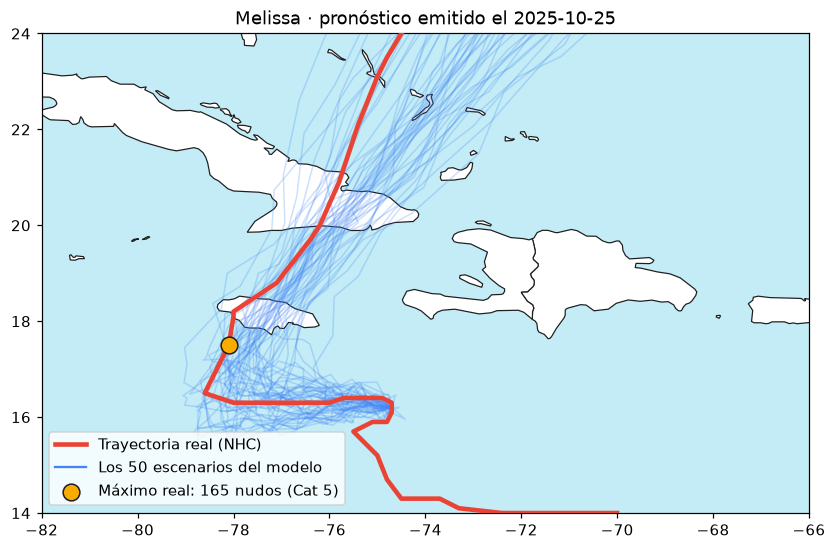

,init_time,track_id,sample,valid_time,lead_time,lead_time_hours,lat,lon,minimum_sea_level_pressure_hpa,maximum_sustained_wind_speed_knots,...,radius_34_knot_winds_sw_km,radius_34_knot_winds_nw_km,radius_50_knot_winds_ne_km,radius_50_knot_winds_se_km,radius_50_knot_winds_sw_km,radius_50_knot_winds_nw_km,radius_64_knot_winds_ne_km,radius_64_knot_winds_se_km,radius_64_knot_winds_sw_km,radius_64_knot_winds_nw_km
0,2025-10-25,AL132025,0,2025-10-25 00:00:00,0 days 00:00:00,0,16.20,-74.70,993.0,54.0,...,56.000000,74.000000,56.000000,74.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000
1,2025-10-25,AL132025,0,2025-10-25 06:00:00,0 days 06:00:00,6,16.08,-75.09,991.7,62.1,...,133.437531,185.534164,106.150649,91.571157,65.588867,85.322806,0.000000,0.000000,0.000000,0.000000
2,2025-10-25,AL132025,0,2025-10-25 12:00:00,0 days 12:00:00,12,16.20,-75.50,987.2,63.3,...,59.059707,107.581039,46.620730,3.663824,0.000000,8.162639,0.000000,0.000000,0.000000,0.000000
3,2025-10-25,AL132025,0,2025-10-25 18:00:00,0 days 18:00:00,18,16.01,-75.92,966.4,89.9,...,115.282725,155.033089,73.855442,59.683831,42.483436,59.556396,32.863979,27.128233,21.085607,28.094148
4,2025-10-25,AL132025,0,2025-10-26 00:00:00,1 days 00:00:00,24,16.07,-76.44,932.4,130.8,...,132.498606,208.175207,101.776530,79.240610,66.616334,94.306026,51.949947,43.753334,38.803840,47.008192


In [4]:
# @title Elige la fecha en que se emitió el pronóstico { run: "auto" }
issue_time = "2025_10_25T00"  # @param ["2025_10_22T00", "2025_10_25T00", "2025_10_27T00"]
# Estos tres pronósticos de Melissa están copiados en data/melissa/ del repositorio.

STORM_ID = "AL132025"                       # Melissa: cuenca AL (Atlántico), tormenta 13, año 2025
MAP_EXTENT = (-82, -66, 14, 24)             # oeste, este, sur, norte (en grados)

ensemble = read_weatherlab(download(f"data/melissa/weatherlab_FNV3P2_ensemble_{issue_time}.csv"), STORM_ID)
best_track = read_best_track(download("data/melissa/nhc_besttrack_AL132025.dat"))
print(f"{ensemble['sample'].nunique()} escenarios · {len(ensemble)} puntos (uno cada 6 horas por escenario)")

fig = plot_forecast(ensemble, best_track, f"Melissa · pronóstico emitido el {issue_time[:10].replace('_', '-')}", MAP_EXTENT)
ensemble.head()   # las primeras filas de la tabla, para que veas cómo es el dato

#### 📖 Cómo leer el mapa
- Cada **línea azul fina** es un escenario: un futuro posible que el modelo consideró.
- La **línea roja** es lo que pasó de verdad. Un buen pronóstico es un abanico azul que **contiene** a la roja.
- Un abanico **estrecho** significa que el modelo estaba seguro; uno **abierto** significa incertidumbre.
- El **punto amarillo** marca dónde Melissa tuvo su viento máximo real.
- En la tabla de abajo, `lead_time_hours` dice cuántas horas después de la emisión corresponde cada punto.

#### 🔎 Qué vemos en el ejemplo (pronóstico del 25 de octubre)
- Los 50 escenarios forman un abanico que cruza Jamaica y la línea roja real queda dentro: **tres días antes**, el modelo ya ponía el impacto en la isla.
- El abanico es más estrecho cerca de Jamaica y se abre más lejos: la incertidumbre crece con las horas de pronóstico.
- En el paso 2 lo convertimos en números: 43 de 50 escenarios pasan a menos de 100 km de Black River.

In [5]:
# Segunda lectura: Gemini mira la figura del mapa
analyze_figure(fig, f"Pronóstico por ensamble del ciclón {STORM_ID} emitido {issue_time} (UTC): líneas azules = "
               f"{ensemble['sample'].nunique()} escenarios del modelo de ciclones de Google DeepMind Weather Lab; "
               "línea roja = trayectoria real (NHC); punto amarillo = viento máximo real.")

   modelo ocupado, reintento 1…


   modelo ocupado, reintento 2…


   modelo ocupado, reintento 3…


**🤖 Análisis de Gemini**

Como analista de gestión de riesgos, aquí tienes el desglose estructurado en viñetas simples, diferenciando claramente los hechos visibles de las interpretaciones prudentes:

**Lo que se VE (Hechos objetivos de la gráfica y el contexto):**
* **Trayectoria oficial y intensidad registrada:** La línea roja muestra el recorrido real del ciclón *Melissa* registrado por el NHC, la cual incluye un punto amarillo que indica un viento máximo real de **165 nudos (Categoría 5)**.
* **Modelo de pronóstico:** Se visualizan 50 líneas delgadas de color azul que corresponden a los escenarios generados por el modelo de Google DeepMind Weather Lab emitidos el 25 de octubre de 2025.
* **Ubicación geográfica actual:** La gráfica abarca la región del Caribe central y las Antillas Mayores (incluyendo Jamaica, Cuba, La Española y Puerto Rico).

**Lo que se INTERPRETA (Análisis de riesgo y prudencia):**
* **Patrón del ensamble:** La gran mayoría de los 50 escenarios azules convergen en una trayectoria que apunta hacia el noreste/norte, pasando sobre el occidente de Cuba y dirigiéndose hacia el Atlántico, coincidiendo en gran medida con el tramo final de la línea roja.
* **Conclusión prudente:** Aunque el modelo muestra alta consistencia en la dirección general hacia el norte (afectando principalmente la zona occidental de Cuba y adyacencias), no se puede determinar con certeza absoluta el punto exacto de impacto ni la intensidad futura de cada escenario únicamente con este mapa de trayectorias.
* **Verificación en terreno indispensable:** Se debe verificar de inmediato con los reportes oficiales de protección civil y meteorología local: el estado real de evacuación de las zonas costeras, la infraestructura crítica vulnerable en la trayectoria prevista, y la disponibilidad de refugios habilitados ante posibles impactos de vientos extremos e inundaciones.

**🧠 Para pensar:** cambia la fecha de emisión en el desplegable (22, 25 o 27 de octubre). ¿Cómo cambia el abanico a medida que se acerca la tormenta?

## Paso 2 · ¿Qué tan probable es que me toque?

Con 50 escenarios, la probabilidad se calcula **contando**: si 40 de 50 pasan a menos de 100 km de un lugar, la probabilidad es del 80 %.
La distancia entre dos puntos de la Tierra se calcula con la **fórmula del haversine**, que tiene en cuenta que la Tierra es una esfera.

In [6]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distancia en km sobre la superficie de la Tierra (radio medio 6371 km)."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(np.asarray(lon2) - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def pass_probability(ensemble, lat, lon, radius_km=100):
    """Cuántos escenarios pasan a menos de radius_km del lugar, con qué viento y cuándo."""
    e = ensemble[ensemble["sample"] >= 0].copy()
    e["dist_km"] = haversine_km(lat, lon, e.lat.values, e.lon.values)
    close = e[e.dist_km <= radius_km]                         # puntos cerca del lugar
    total = e["sample"].nunique()                             # escenarios en total
    hits = close["sample"].nunique()                          # escenarios que pasan cerca
    winds = close.groupby("sample").maximum_sustained_wind_speed_knots.max()   # viento de cada uno al pasar
    return {
        "scenarios": total,
        "hits": hits,
        "probability": hits / total if total else 0.0,
        "median_wind_kt": float(winds.median()) if hits else None,
        "prob_cat5": float((winds >= 137).sum() / total) if total else 0.0,
        "most_likely_arrival": close.groupby("sample").valid_time.min().median() if hits else None,
    }


# Lugares de ejemplo (latitud, longitud). Añade el tuyo: búscalo en Google Maps,
# haz clic derecho sobre el mapa y copia las coordenadas que aparecen arriba del menú.
PLACES = {
    "Black River, Jamaica": (18.026, -77.850),
    "Kingston, Jamaica": (17.997, -76.794),
    "Santo Domingo, RD": (18.486, -69.931),
    "Santiago, RD": (19.451, -70.697),
    "Puerto Príncipe, Haití": (18.594, -72.307),
}

In [7]:
# @title Elige un lugar { run: "auto" }
place = "Black River, Jamaica"  # @param ["Black River, Jamaica", "Kingston, Jamaica", "Santo Domingo, RD", "Santiago, RD", "Puerto Príncipe, Haití", "Mis coordenadas"]
my_lat = 18.4861    # @param {type:"number"}
my_lon = -69.9312   # @param {type:"number"}
radius_km = 100  # @param {type:"slider", min:25, max:300, step:25}
# Para usar tu lugar: elige «Mis coordenadas» y escribe latitud y longitud (en Google Maps, clic derecho sobre el mapa).

lat, lon = (my_lat, my_lon) if place == "Mis coordenadas" else PLACES[place]
p = pass_probability(ensemble, lat, lon, radius_km)
print(f"📍 {place}")
print(f"   {p['hits']} de {p['scenarios']} escenarios pasan a menos de {radius_km} km → probabilidad {p['probability']:.0%}")
if p["hits"]:
    print(f"   Viento máximo típico al pasar: {p['median_wind_kt']:.0f} nudos ({saffir_simpson(p['median_wind_kt'])})")
    print(f"   Probabilidad de que llegue como categoría 5: {p['prob_cat5']:.0%}")
    print(f"   Momento más probable: {p['most_likely_arrival']:%d-%b %H:%M} UTC")

📍 Black River, Jamaica
   43 de 50 escenarios pasan a menos de 100 km → probabilidad 86%
   Viento máximo típico al pasar: 130 nudos (Cat 4)
   Probabilidad de que llegue como categoría 5: 28%
   Momento más probable: 28-Oct 12:00 UTC


#### 📖 Cómo leer el resultado
- **Probabilidad**: la fracción de escenarios que pasa a menos del radio elegido. No dice *si* el huracán llegará, sino **cuántos de los futuros posibles** lo traen.
- **Viento máximo típico**: la mediana del viento de los escenarios que pasan cerca, en nudos y como categoría Saffir-Simpson.
- **Categoría 5**: qué fracción de **todos** los escenarios pasa cerca con vientos de 137 nudos o más.
- **Momento más probable**: hora UTC. En República Dominicana y en Jamaica, resta 4 y 5 horas respectivamente.
- Prueba un **radio mayor**: la probabilidad sube, porque estás preguntando por una zona más grande.

#### 🔎 Qué vemos en el ejemplo (Black River, pronóstico del 25 de octubre, radio de 100 km)
- **86 %** (43 de 50 escenarios) pasa cerca: tres días antes, la amenaza sobre el suroeste de Jamaica era muy clara.
- Viento típico de **130 nudos (categoría 4)** y **28 %** de escenarios en categoría 5. En la realidad Melissa tocó tierra con **160 nudos, categoría 5**: el modelo acertó el lugar, subestimó algo la intensidad, pero ya avisaba de que una categoría 5 era posible.
- Momento más probable: **28 de octubre a las 12:00 UTC**. Melissa tocó tierra ese día hacia las 17:00 UTC: unas horas de diferencia con tres días de antelación.
- Cambia el lugar a Santo Domingo y compara: la probabilidad baja mucho.

In [8]:
# Segunda lectura: Gemini analiza los números
analyze_data(p, f"Probabilidad de que el ojo del ciclón pase a menos de {radius_km} km de {place}, calculada contando "
                f"escenarios del pronóstico emitido {issue_time}. Viento en nudos (137 o más = categoría 5). Horas en UTC. "
                "Trayectoria real de Melissa: tocó tierra en Jamaica el 28-oct-2025 hacia las 17 UTC con 160 nudos.")

   modelo ocupado, reintento 1…


   modelo ocupado, reintento 2…


   modelo ocupado, reintento 3…


**🤖 Análisis de Gemini**

Como analista de gestión de riesgos, aquí tienes el análisis basado estrictamente en los datos del pronóstico del 25 de octubre de 2025 (00 UTC) para Black River, Jamaica:

*   **Lo que se ve (Datos):** El modelo analizó 50 escenarios posibles (trayectorias simuladas), de los cuales 43 indican que el ojo del ciclón pasará a menos de 100 km de Black River, arrojando una probabilidad matemática del 86%.
*   **Lo que se ve (Datos):** La mediana de la velocidad del viento proyectada en esos escenarios es de 130.3 nudos, y existe una probabilidad del 28% (14 de 50 escenarios) de que alcance la categoría 5 (137 nudos o más).
*   **Lo que se ve (Datos):** La hora de llegada más probable del fenómeno según el pronóstico es el 28 de octubre de 2025 a las 12:00 UTC. (Nota: La trayectoria *real* posterior mostró que tocó tierra el 28 de octubre a las 17 UTC con 160 nudos).
*   **Lo que se interpreta (Patrón y conclusión):** El modelo mostraba un riesgo alto y inminente (86% de probabilidad de impacto cercano y vientos intensos cercanos a categoría 5), anticipando acertadamente el día del impacto real, aunque con una ligera diferencia de 5 horas y mayor intensidad final de la que marcaba la mediana.
*   **Qué habría que verificar en terreno:** Es necesario realizar una evaluación rápida de daños en la infraestructura costera, el estado de los refugios temporales y la operatividad de los sistemas de alerta temprana en Black River tras el impacto real de 160 nudos.
*   **Qué NO se puede saber con estos datos:** Con este resumen estadístico no es posible saber la distribución geográfica exacta de las inundaciones costeras, los daños específicos en viviendas ni el impacto en sectores agrícolas locales de Jamaica.

## 🌊 Y los ríos: Flood Hub (para explorar en el navegador)

**Flood Hub** pronostica crecidas de ríos hasta 7 días antes en más de 150 países, incluso en ríos **sin estaciones de medición**,
con dos redes neuronales LSTM en cadena. Su API requiere una key aprobada por Google, así que en este taller no la usamos desde código.
Puedes explorarlo en el navegador: abre [sites.research.google/floods](https://sites.research.google/floods) y busca un río de tu país.

## Paso 3 · De los números a una alerta

Un pronóstico excelente no salva a nadie si la persona no lo entiende. Le pasamos a **Gemini** los números de los pasos anteriores y él redacta la alerta siguiendo reglas claras.
La alerta lleva tres campos del **Protocolo Común de Alertas (CAP)**: severidad, urgencia y certeza. CAP es el estándar con el que las autoridades publican alertas, y es el formato que Google usa para mostrarlas en Búsqueda y Maps.

La celda siguiente define cómo conectarse a Gemini, las reglas de redacción y cómo se dibuja la alerta.

In [9]:
# ---------------------------------------------------------------- la alerta
# Las "instrucciones de sistema" son las reglas fijas del modelo. Cámbialas y vuelve a ejecutar.
ALERT_INSTRUCTIONS = """Eres el redactor de alertas de una oficina de protección civil del Caribe.
Recibes datos técnicos y escribes UNA alerta para la población, en español sencillo.
Reglas:
- Se tiene que entender en 3 segundos: primero QUÉ pasa, luego DÓNDE, luego QUÉ HACER.
- Máximo 280 caracteres en el campo 'mensaje'. Sin tecnicismos (nada de nudos, hPa, NDVI ni dB).
- No inventes datos que no estén en la entrada. Si la certeza es baja, dilo.
- Incluye los campos del Protocolo Común de Alertas (CAP): severidad, urgencia y certeza.
"""

# El "esquema" obliga al modelo a responder con un JSON con estos campos exactos.
# severidad, urgencia y certeza usan los valores oficiales del estándar CAP (en inglés).
ALERT_SCHEMA = {
    "type": "object",
    "properties": {
        "titulo": {"type": "string"},
        "mensaje": {"type": "string"},
        "que_hacer": {"type": "array", "items": {"type": "string"}},
        "severidad": {"type": "string", "enum": ["Extreme", "Severe", "Moderate", "Minor", "Unknown"]},
        "urgencia": {"type": "string", "enum": ["Immediate", "Expected", "Future", "Past", "Unknown"]},
        "certeza": {"type": "string", "enum": ["Observed", "Likely", "Possible", "Unlikely", "Unknown"]},
    },
    "required": ["titulo", "mensaje", "que_hacer", "severidad", "urgencia", "certeza"],
}


def write_alert(client, model, technical_data):
    """Convierte un diccionario de números en una alerta estructurada (un dict con los campos del esquema)."""
    content = "Datos técnicos:\n" + json.dumps(technical_data, ensure_ascii=False, default=str, indent=1)
    if "gemma" in model:
        # Gemma no admite instrucciones de sistema ni esquema por la API: lo pedimos todo en el texto.
        prompt = (ALERT_INSTRUCTIONS + "\nResponde SOLO con un JSON con las claves "
                  + ", ".join(ALERT_SCHEMA["required"]) + ". 'que_hacer' es una lista de frases cortas. "
                  + "severidad: Extreme|Severe|Moderate|Minor|Unknown; urgencia: Immediate|Expected|Future|Past|Unknown; "
                  + "certeza: Observed|Likely|Possible|Unlikely|Unknown (en inglés, tal cual).\n\n" + content)
        text = generate(client, model, prompt).text.strip()
        return json.loads(text.removeprefix("```json").removeprefix("```").removesuffix("```"))
    config = types.GenerateContentConfig(system_instruction=ALERT_INSTRUCTIONS,
                                         response_mime_type="application/json",
                                         response_json_schema=ALERT_SCHEMA,
                                         temperature=0.2)   # temperatura baja = respuestas más estables
    return json.loads(generate(client, model, content, config).text)


def show_alert(alert):
    """Dibuja la alerta como una notificación de teléfono."""
    from IPython.display import HTML, display
    colors = {"Extreme": "#ea4335", "Severe": "#f9ab00", "Moderate": "#4285f4", "Minor": "#34a853"}
    color = colors.get(alert.get("severidad"), "#1e1e1e")
    steps = alert.get("que_hacer", [])
    if isinstance(steps, str):          # a veces Gemma devuelve una frase en vez de una lista
        steps = [s.strip() for s in steps.replace(";", ".").split(".") if s.strip()]
    items = "".join(f"<li>{s}</li>" for s in steps)
    display(HTML(f"""
    <div style="max-width:380px;border:2px solid #1e1e1e;border-radius:28px;padding:20px 24px;
                font-family:'Google Sans',system-ui,sans-serif;background:#fff;color:#1e1e1e">
      <div style="display:inline-block;background:{color};color:#fff;border-radius:999px;padding:4px 14px;
                  font-size:13px">{alert.get('severidad')} · {alert.get('urgencia')} · {alert.get('certeza')}</div>
      <h3 style="margin:12px 0 6px">{alert.get('titulo')}</h3>
      <p style="font-size:16px;margin:0 0 8px">{alert.get('mensaje')}</p>
      <ul style="margin:0;padding-left:20px">{items}</ul>
    </div>"""))

print("Funciones de Gemini listas ✅")

Funciones de Gemini listas ✅


In [10]:
client = gemini_client()
model = pick_model(client, "flash")
print("Modelo:", model)

# Estos son TODOS los datos que recibe el modelo. Si no está aquí, no debería aparecer en la alerta.
technical_data = {
    "evento": "Huracán Melissa",
    "pronostico_emitido": issue_time,
    "lugar": place,
    "probabilidad_paso": {"radio_km": radius_km, "probabilidad": round(p["probability"], 2)},
    "viento_esperado": saffir_simpson(p["median_wind_kt"] or 0),
    "probabilidad_categoria_5": round(p["prob_cat5"], 2),
    "llegada_mas_probable_utc": p["most_likely_arrival"],
}
alert = write_alert(client, model, technical_data)
show_alert(alert)
alert   # el JSON tal cual: esto es lo que otro sistema (SMS, WhatsApp, sirena) leería

Modelo: gemini-flash-latest
   modelo ocupado, reintento 1…


   modelo ocupado, reintento 2…


   modelo ocupado, reintento 3…


{'titulo': 'Alerta de Huracán Melissa',
 'mensaje': 'Huracán categoría 4 se acerca a Black River, Jamaica. Impacto muy probable el 28 de octubre. Proteja su vida y propiedades de inmediato.',
 'que_hacer': ['Evacue si las autoridades se lo indican',
  'Asegure puertas y ventanas',
  'Tenga lista una mochila de emergencia'],
 'severidad': 'Extreme',
 'urgencia': 'Immediate',
 'certeza': 'Likely'}

#### 📖 Cómo leer la alerta
- La **etiqueta de color** resume los tres campos del estándar CAP: **severidad** (*Extreme* = amenaza extraordinaria para la vida; *Severe* = amenaza significativa; *Moderate*, *Minor*), **urgencia** (*Immediate* = actuar ya; *Expected* = en la próxima hora o pocas horas; *Future* = más adelante) y **certeza** (*Observed* = ya está pasando; *Likely* = más del 50 %; *Possible* = menos del 50 %).
- Revisa que el **mensaje** diga primero qué pasa, luego dónde y luego qué hacer, y que no tenga cifras técnicas.
- Comprueba que **no inventó nada**: todo lo que diga tiene que estar en el diccionario de datos que le pasaste. Si ves un dato nuevo (una hora, un refugio, un número), es una alucinación.
- Cada vez que ejecutes la celda la redacción cambia un poco: es normal en un modelo de lenguaje.

### 🧪 La misma alerta con Gemma, un modelo abierto

**Gemma** es la familia de modelos abiertos de Google. Sus versiones pequeñas corren **sin internet**, en un teléfono o una Raspberry Pi.
Así lo hizo *Acuífero·Vigía*, ganador del premio Global Resilience del Gemma 4 Good Challenge: un sistema de alerta de inundaciones que funciona sin conexión.
¿La alerta de Gemma es tan buena como la de Gemini?

In [11]:
gemma_model = pick_model(client, "gemma")
print("Modelo:", gemma_model)
show_alert(write_alert(client, gemma_model, technical_data))

Modelo: gemma-4-26b-a4b-it


## Paso 4 · 🔧 Adapta el cuaderno

### a) Tu ciudad
En la celda de `PLACES` añade una línea con tu lugar, por ejemplo `"La Romana, RD": (18.427, -68.972),`, ejecútala y añade el mismo nombre a la lista entre corchetes de `# @param` en la celda de *Elige un lugar*.

### b) Otro huracán (datos en vivo)
La celda de abajo descarga **directamente de Weather Lab y del NHC** cualquier tormenta, sin pasar por el repositorio. Necesitas tres datos:

| Dato | Qué es | Dónde se encuentra |
|---|---|---|
| `STORM_ID` | Identificador ATCF: cuenca + número de dos cifras + año. `AL` = Atlántico, `EP` = Pacífico este | En la página de la tormenta en [nhc.noaa.gov](https://www.nhc.noaa.gov) o en Wikipedia (*"ATCF ID"*). Ejemplos: Beryl 2024 = `AL022024`, Milton 2024 = `AL142024`, Fiona 2022 = `AL072022` |
| `ISSUE_TIME` | Fecha y hora de emisión del pronóstico, con el formato `AAAA_MM_DDTHH`. Weather Lab emite a las `00`, `06`, `12` y `18` UTC | Elige un momento en que la tormenta ya existía, unos días antes del impacto que te interesa |
| `MAP_EXTENT` | Qué parte del mapa mostrar: (oeste, este, sur, norte) | Déjalo en `None` y se calcula solo a partir de la trayectoria real |

Notas:
- La trayectoria real se baja del archivo histórico del NHC (`ftp.nhc.noaa.gov/atcf/archive/AÑO/`), que tiene las tormentas de **temporadas ya cerradas**.
- Los pronósticos de Weather Lab de las últimas 48 horas tienen sus propios términos de uso; los anteriores tienen licencia **CC BY 4.0**.
- El mapa de fondo solo trae el Caribe, Centroamérica, México y EE. UU.: para el Pacífico verás las líneas sin costas.

⬇️  live/weatherlab_FNV3P2_2024_07_01T00.csv · 0.5 MB


⬇️  live/nhc_AL022024.dat.gz · 0.0 MB


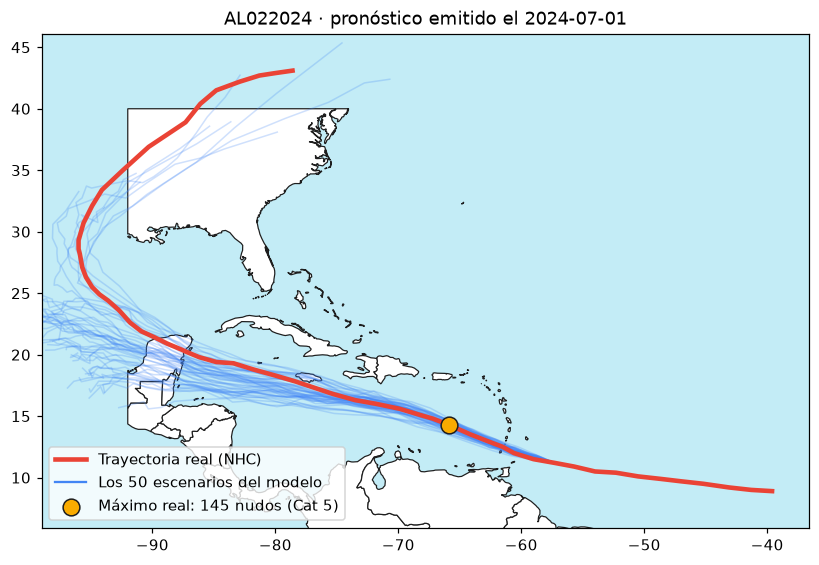

In [12]:
# @title Otro huracán, en vivo
STORM_ID = "AL022024"          # @param {type:"string"}
ISSUE_TIME = "2024_07_01T00"   # @param {type:"string"}
MODEL = "FNV3P2"               # el modelo experimental de ciclones de Weather Lab
MAP_EXTENT = None

# La dirección de descarga de Weather Lab sigue siempre este patrón:
weatherlab_url = ("https://deepmind.google.com/science/weatherlab/download/cyclones/"
                  f"{MODEL}/ensemble/paired/csv/{MODEL}_{ISSUE_TIME}_00_paired.csv")
year = STORM_ID[-4:]
nhc_url = f"https://ftp.nhc.noaa.gov/atcf/archive/{year}/b{STORM_ID[:2].lower()}{STORM_ID[2:].lower()}.dat.gz"

ensemble = read_weatherlab(download(f"live/weatherlab_{MODEL}_{ISSUE_TIME}.csv", weatherlab_url), STORM_ID)
best_track = read_best_track(download(f"live/nhc_{STORM_ID}.dat.gz", nhc_url))
if ensemble.empty:
    print(f"⚠️ El pronóstico de {ISSUE_TIME} no incluye {STORM_ID}. Prueba otra fecha en la que la tormenta ya existiera.")
else:
    if MAP_EXTENT is None:   # la trayectoria real con 3 grados de margen
        MAP_EXTENT = (best_track.lon.min() - 3, best_track.lon.max() + 3, best_track.lat.min() - 3, best_track.lat.max() + 3)
    plot_forecast(ensemble, best_track, f"{STORM_ID} · pronóstico emitido el {ISSUE_TIME[:10].replace('_', '-')}", MAP_EXTENT)
    # Después de esta celda, vuelve a ejecutar las del paso 2 y 3: usarán este huracán.
    # (Cambia también "evento" en technical_data por el nombre de la tormenta.)

### c) Otro idioma u otras reglas para la alerta
`ALERT_INSTRUCTIONS` es un texto normal. Cámbialo y vuelve a ejecutar la celda de la alerta. La celda de abajo, por ejemplo, la pide en creole haitiano.

In [13]:
ALERT_INSTRUCTIONS = ALERT_INSTRUCTIONS.replace("en español sencillo", "en creole haitiano sencillo")
print(ALERT_INSTRUCTIONS)
# Ahora vuelve a ejecutar la celda que llama a write_alert(...)

Eres el redactor de alertas de una oficina de protección civil del Caribe.
Recibes datos técnicos y escribes UNA alerta para la población, en creole haitiano sencillo.
Reglas:
- Se tiene que entender en 3 segundos: primero QUÉ pasa, luego DÓNDE, luego QUÉ HACER.
- Máximo 280 caracteres en el campo 'mensaje'. Sin tecnicismos (nada de nudos, hPa, NDVI ni dB).
- No inventes datos que no estén en la entrada. Si la certeza es baja, dilo.
- Incluye los campos del Protocolo Común de Alertas (CAP): severidad, urgencia y certeza.



## 🏁 Retos (si te sobra tiempo)
1. Emite la alerta para **Santo Domingo** con el pronóstico del **22 de octubre**. ¿Qué certeza le pone Gemini? ¿Tiene sentido?
2. ¿Cuántos escenarios predijeron categoría 5 en Jamaica el 22 de octubre? ¿Y el 27?
3. Carga **Beryl** (`AL022024`) emitido el `2024_06_30T00` y calcula la probabilidad para Kingston.

## 🆘 Si algo falla

| Lo que ves | Qué hacer |
|---|---|
| `NameError: name '...' is not defined` | Te saltaste una celda: cada paso usa funciones definidas antes. Usa **Runtime → Run before** (*Entorno de ejecución → Ejecutar anteriores*). |
| `ModuleNotFoundError` | Ejecuta otra vez la primera celda (la que instala librerías). |
| `No encuentro tu key` o `Falta GOOGLE_API_KEY` | Revisa el bloque 🔑: el nombre debe ser exactamente `GOOGLE_API_KEY` y *Notebook access* debe estar activo. |
| `429` o `RESOURCE_EXHAUSTED` | Llegaste al límite gratuito por minuto. Espera un minuto y vuelve a ejecutar la celda. |
| `503` o `UNAVAILABLE` | El modelo está saturado. El código reintenta solo; si aun así falla, prueba de nuevo en un minuto. |
| `HTTP Error 404` al descargar | La dirección no existe: revisa la fecha o el identificador que escribiste. |
| Una celda tarda mucho | Las celdas con `LIVE = True` leen datos en directo y dependen de la red. Ponlas en `False` para usar la copia guardada en GitHub. |
| Todo se rompió | **Runtime → Restart session** y ejecuta de nuevo desde la primera celda. |

---
**Fuentes y licencias.** Pronósticos: Google DeepMind Weather Lab, modelo experimental de ciclones; datos históricos con licencia CC BY 4.0. Es un pronóstico de investigación, no un producto oficial.
Trayectoria real: NOAA / National Hurricane Center (best track, dominio público). Contornos: Natural Earth.
**Para alertas reales, consulta siempre a tu servicio meteorológico nacional.**